In [2]:
import glob
import h5py
from tqdm import tqdm
import numpy as np
from matplotlib import pyplot as plt
import os

In [3]:
def read_files(glob_pattern, minyear=0, maxyear=999):
    files = glob.glob(glob_pattern)
    angles = []

    for fpath in tqdm(files):
        year = int(os.path.basename(fpath)[:4])
        if year > maxyear:
            continue
        if year < minyear:
            continue

        hdf = h5py.File(fpath)
        angles.extend(hdf['angles_deg'][:].flatten())
        hdf.close()
    
    return np.array(angles)

In [5]:
angles_samples = read_files('../data/validation/angle_samples/*.hdf5', maxyear=2020)

100%|█████████████████████████████████████████████████████████████████████████| 835/835 [00:02<00:00, 416.40it/s]


In [4]:
angles_testdata = read_files('../data/validation/angle_testdata/*.hdf5', maxyear=2020)

100%|█████████████████████████████████████████████████████████████████████████| 835/835 [00:02<00:00, 413.55it/s]


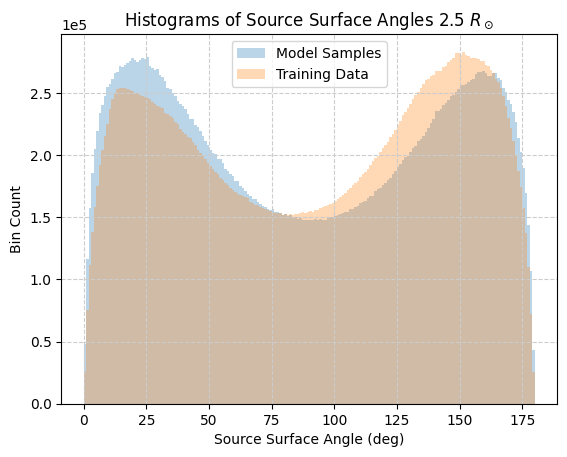

In [7]:
bins = np.arange(0, 181, 1)


plt.hist(angles_samples, bins=bins, label='Model Samples', alpha=0.3)
plt.hist(angles_testdata, bins=bins, label='Training Data', alpha=0.3)

plt.legend()
plt.ylabel('Bin Count')
plt.xlabel('Source Surface Angle (deg)')
plt.title(r'Histograms of Source Surface Angles 2.5 $R_\odot$')
plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
plt.grid(linestyle='dashed', color='#ccc')